(gpt2_pretrained)=
# Fine-tuning a pretrained GPT-2 with LoRA

This example loads GPT-2 small from Hugging Face, checks its next-token predictions, and fine-tunes it on sitcom scripts by adding low-rank adapters to its weights. The adapters are added by editing the loaded graph, and the same edit is applied to a training graph and an inference graph that share one set of weights.

In [1]:
import pytensor

floatX = "float32"
pytensor.config.floatX = floatX

In [2]:
import csv
import json
import urllib.request

from itertools import groupby
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pytensor.tensor as pt

from huggingface_hub import snapshot_download
from huggingface_hub.utils import disable_progress_bars
from pytensor.graph.replace import graph_replace
from tokenizers import Tokenizer
from tqdm.auto import tqdm

from pytensor_ml import from_pretrained
from pytensor_ml.loss import CrossEntropy
from pytensor_ml.optim import (
    adam,
    compile_train,
    cosine_schedule,
    join_schedules,
    linear_schedule,
)
from pytensor_ml.params import trainable
from pytensor_ml.pytensorf import collect_trainable_params, rebuild

:::{include} /_includes/extra_installs.md
:::

## Loading the checkpoint

The checkpoint is GPT-2 small {cite:p}`radford2019language`. {func}`~pytensor_ml.from_pretrained` builds the network from the checkpoint's config and fills its weights, returning the token-id input and the outputs, logits first.

In [3]:
disable_progress_bars()

checkpoint_dir = Path(
    snapshot_download(
        repo_id="openai-community/gpt2",
        allow_patterns=["config.json", "model.safetensors", "tokenizer.json"],
    )
)
n_positions = json.loads((checkpoint_dir / "config.json").read_text())["n_positions"]
sorted(path.name for path in checkpoint_dir.iterdir())

['config.json', 'model.safetensors', 'tokenizer.json']

In [4]:
inputs, outputs = from_pretrained(checkpoint_dir)
input_ids = inputs[0]
logits = outputs[0]

n_parameters = sum(parameter.get_value().size for parameter in collect_trainable_params(logits))
input_ids.type, logits.type, f"{n_parameters:,} parameters"

(TensorType(int64, shape=(None, None)),
 TensorType(float32, shape=(None, None, 50257)),
 '124,439,808 parameters')

## Next-token prediction

GPT-2's tokenizer marks a leading space with `Ġ`, so `ĠParis` is the word " Paris" with its space attached.

In [5]:
tokenizer = Tokenizer.from_file(str(checkpoint_dir / "tokenizer.json"))

prompt = "The capital of France is"
encoding = tokenizer.encode(prompt)
list(zip(encoding.tokens, encoding.ids))

[('The', 464),
 ('Ġcapital', 3139),
 ('Ġof', 286),
 ('ĠFrance', 4881),
 ('Ġis', 318)]

In [6]:
next_token_probabilities = pytensor.function(
    inputs=[input_ids], outputs=pt.special.softmax(logits[0, -1])
)

probabilities = next_token_probabilities(np.array([encoding.ids]))
top_ids = np.argsort(probabilities)[::-1][:10]

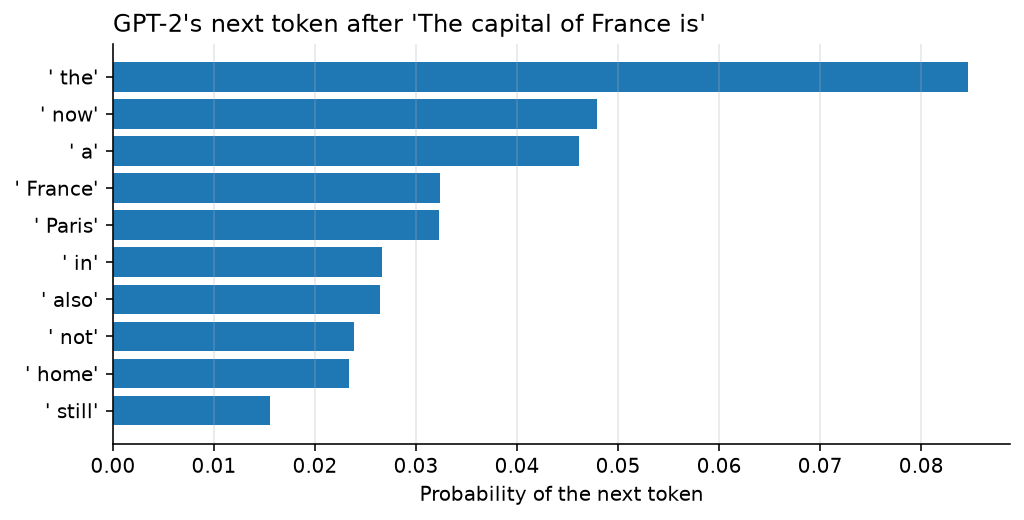

In [7]:
top_tokens = [repr(tokenizer.decode([token_id])) for token_id in top_ids]

fig, ax = plt.subplots(figsize=(7, 3.5), dpi=144, layout="constrained")
ax.barh(top_tokens[::-1], probabilities[top_ids][::-1], color="C0")
ax.set(xlabel="Probability of the next token")
ax.set_title(f"GPT-2's next token after {prompt!r}", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.show()

## Fine-tuning on a new domain

A pretrained model has learned general English, and fine-tuning adapts it to a narrower kind of text. Updating all 124 million weights is expensive, so low-rank adaptation (LoRA) {cite:p}`hu2022lora` trains a small correction to selected weight matrices and leaves the pretrained weights frozen. The loaded model is a PyTensor graph, so adding those corrections takes no changes to the model code. Each weight is swapped for its corrected version with a graph substitution, and the rest of the network stays as it was loaded.

The target domain here is dialogue from the sitcom *Seinfeld*. The scripts come as one row per spoken line, with the speaker and the episode. Each episode becomes a block of `Speaker: line` turns, and the last tenth of the episodes is held out for validation.

In [8]:
DATA_URL = "https://raw.githubusercontent.com/4m4n5/the-seinfeld-chronicles/master/scripts.csv"
data_path = Path("../data/seinfeld_scripts.csv")

if not data_path.exists():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, data_path)

with data_path.open(encoding="utf-8") as file:
    rows = list(csv.DictReader(file))

episodes = [
    "\n".join(f"{row['Character'].title()}: {row['Dialogue'].strip()}" for row in lines)
    for _, lines in groupby(rows, key=lambda row: row["SEID"])
]
n_train_episodes = int(0.9 * len(episodes))

train_ids = np.array(tokenizer.encode("\n\n".join(episodes[:n_train_episodes])).ids, dtype=np.int64)
val_ids = np.array(tokenizer.encode("\n\n".join(episodes[n_train_episodes:])).ids, dtype=np.int64)
len(episodes), len(train_ids), len(val_ids)

(173, 864328, 111475)

In [9]:
block_size = 256
batch_size = 8
rng = np.random.default_rng(sum(map(ord, "gpt2 lora")))


def get_batch(ids, *, rng, block_size, batch_size):
    starts = rng.integers(len(ids) - block_size, size=batch_size)
    windows = starts[:, None] + np.arange(block_size)
    return ids[windows], ids[windows + 1]

## A fixed-shape training graph

MLX compiles only graphs whose shapes are known, and the loaded graph accepts any batch size and sequence length. {func}`~pytensor_ml.pytensorf.rebuild` remakes it for a fixed batch, sharing the same weights.

In [10]:
train_tokens = pt.tensor("train_tokens", shape=(batch_size, block_size), dtype="int64")
train_logits = rebuild(logits, {input_ids: train_tokens})
train_logits.type

TensorType(float32, shape=(8, 256, 50257))

## LoRA adapters

Fine-tuning changes each weight matrix $W$ by some update $\Delta W$. LoRA restricts that update to low rank, writing it as the product of two thin matrices,

$$
W' = W + \frac{\alpha}{r} A B, \qquad A \in \mathbb{R}^{d_\text{in} \times r}, \quad B \in \mathbb{R}^{r \times d_\text{out}},
$$

with the rank $r$ far smaller than either dimension. $A$ projects the input down to rank $r$ and $B$ projects it back up, so the code calls them `down` and `up`. The bet is that adapting a pretrained model to a new domain needs only a few new directions in each weight matrix.

The restriction buys several things. With $r = 8$, a $768 \times 3072$ MLP weight gets about 31,000 trainable parameters in place of 2.4 million, so the optimizer state that Adam keeps for every trained parameter shrinks by the same factor. The pretrained weights never change, so one copy of GPT-2 can serve any number of adapters, each small enough to save and share on its own. After training, $\frac{\alpha}{r} A B$ can be added into $W$, which leaves a network with the original architecture and no extra cost at inference.

$B$ starts at zero, so the adapted network starts out identical to the pretrained one, and $A$ starts random so that the gradient with respect to $B$ is not zero. The factor $\frac{\alpha}{r}$ keeps the size of the update roughly the same when $r$ changes. Here every linear weight in the attention and MLP layers gets an adapter.

In [11]:
rank = 8
alpha = 16
adapted_layers = ("attn_qkv_proj_W", "attn_out_proj_W", "ff_fc_in_W", "ff_fc_out_W")

lora_parameters = []
lora_replacements = {}
for weight in collect_trainable_params(train_logits):
    if not weight.name.endswith(adapted_layers):
        continue

    n_in, n_out = weight.get_value().shape
    down = trainable(
        rng.normal(scale=0.02, size=(n_in, rank)).astype(floatX), name=f"{weight.name}_lora_down"
    )
    up = trainable(np.zeros((rank, n_out), dtype=floatX), name=f"{weight.name}_lora_up")

    lora_parameters += [down, up]
    lora_replacements[weight] = weight + (alpha / rank) * (down @ up)

n_lora = sum(parameter.get_value().size for parameter in lora_parameters)
f"{len(lora_replacements)} adapted weights, {n_lora:,} trainable parameters"

'48 adapted weights, 1,179,648 trainable parameters'

In [12]:
n_steps = 1000
warmup_steps = 100

learning_rate = join_schedules(
    [
        linear_schedule(0.0, total_steps=warmup_steps, final_learning_rate=1e-3),
        cosine_schedule(1e-3, total_steps=n_steps - warmup_steps, final_learning_rate=1e-4),
    ],
    boundaries=[warmup_steps],
)

targets = pt.tensor("targets", shape=(batch_size, block_size), dtype="int64")

lora_logits = graph_replace(train_logits, lora_replacements)
loss = CrossEntropy(expect_logits=True)(targets, lora_logits)

lora_step = compile_train(
    loss,
    adam(learning_rate=learning_rate),
    parameters=lora_parameters,
    inputs=[train_tokens, targets],
    compile_kwargs={"mode": "MLX"},
)

## Sampling before fine-tuning

The inference graph gets the same substitution as the training graph. Every `up` matrix starts at zero, so before training this samples plain GPT-2.

In [13]:
script_prompt = (
    "Jerry: You ever notice nobody actually reads the terms and conditions?\n"
    "Elaine: I read them once. It took me a whole weekend.\n"
    "George:"
)

In [14]:
lora_next_token_logits = pytensor.function(
    inputs=[input_ids], outputs=graph_replace(logits, lora_replacements)[0, -1]
)


def generate(prompt, *, n_tokens, temperature, seed):
    sample_rng = np.random.default_rng(seed)
    ids = tokenizer.encode(prompt).ids
    for _ in range(n_tokens):
        scaled = lora_next_token_logits(np.array([ids[-n_positions:]])) / temperature
        probabilities = np.exp(scaled - scaled.max())
        ids.append(sample_rng.choice(len(probabilities), p=probabilities / probabilities.sum()))
    return tokenizer.decode(ids)

In [15]:
for seed in range(3):
    print(f"--- sample {seed + 1} ---")
    print(generate(script_prompt, n_tokens=120, temperature=0.8, seed=seed), end="\n\n")

--- sample 1 ---
Jerry: You ever notice nobody actually reads the terms and conditions?
Elaine: I read them once. It took me a whole weekend.
George: What's the time machine going to say?
George: Oh, what the hell?
Elaine: For one thing, damn quick. I'm out of here.
George: Okay, man, you're off to a great start. I think we can all stop talking about that.
Elaine: Yup, sorry.
George: How'd you get into blogging when you think you're doing it at home and you're bringing friends, taking assignments from me as well?
Elaine: I'm not bringing any friends.
George: Why do you have friends?

--- sample 2 ---
Jerry: You ever notice nobody actually reads the terms and conditions?
Elaine: I read them once. It took me a whole weekend.
George: No really, George.
George: As a kid, I'd say that the most important thing you can do when running is to get to almost your own goal.
George: No, I'd say that. We're just trying to keep those goals in check.
George: Yeah, I was having some trouble with that. 

## Training

Only the adapter matrices train, on MLX. The learning rate rises linearly to $10^{-3}$ over the first 100 steps, then follows a cosine decay to $10^{-4}$. The run is 1,000 steps of 8 windows of 256 tokens, about 2.4 passes over the training episodes. Much longer runs overfit the adapters to the training episodes, and the validation loss turns back up while the training loss keeps falling. Training and validation loss are measured on the same fixed batches at every evaluation, so the curves move only because the adapters change.

In [16]:
evaluate_loss = pytensor.function(inputs=[train_tokens, targets], outputs=loss, mode="MLX")

n_eval_batches = 10
eval_rng = np.random.default_rng(sum(map(ord, "gpt2 lora eval")))
batch_shape = {"block_size": block_size, "batch_size": batch_size}
train_eval_batches = [
    get_batch(train_ids, rng=eval_rng, **batch_shape) for _ in range(n_eval_batches)
]
val_eval_batches = [get_batch(val_ids, rng=eval_rng, **batch_shape) for _ in range(n_eval_batches)]

In [17]:
eval_interval = 100

step_losses = []
eval_steps, train_loss, val_loss = [], [], []

for step_number in tqdm(range(n_steps + 1)):
    if step_number % eval_interval == 0:
        eval_steps.append(step_number)
        train_loss.append(np.mean([np.array(evaluate_loss(X, y)) for X, y in train_eval_batches]))
        val_loss.append(np.mean([np.array(evaluate_loss(X, y)) for X, y in val_eval_batches]))

    if step_number == n_steps:
        break

    # MLX evaluates lazily, so the step only runs, and its updates only land, once its output is read.
    X_batch, y_batch = get_batch(train_ids, rng=rng, **batch_shape)
    step_losses.append(np.array(lora_step(X_batch, y_batch)))

print(f"validation loss {val_loss[0]:.3f} before fine-tuning, {val_loss[-1]:.3f} after")

  0%|          | 0/1001 [00:00<?, ?it/s]

validation loss 3.127 before fine-tuning, 2.885 after


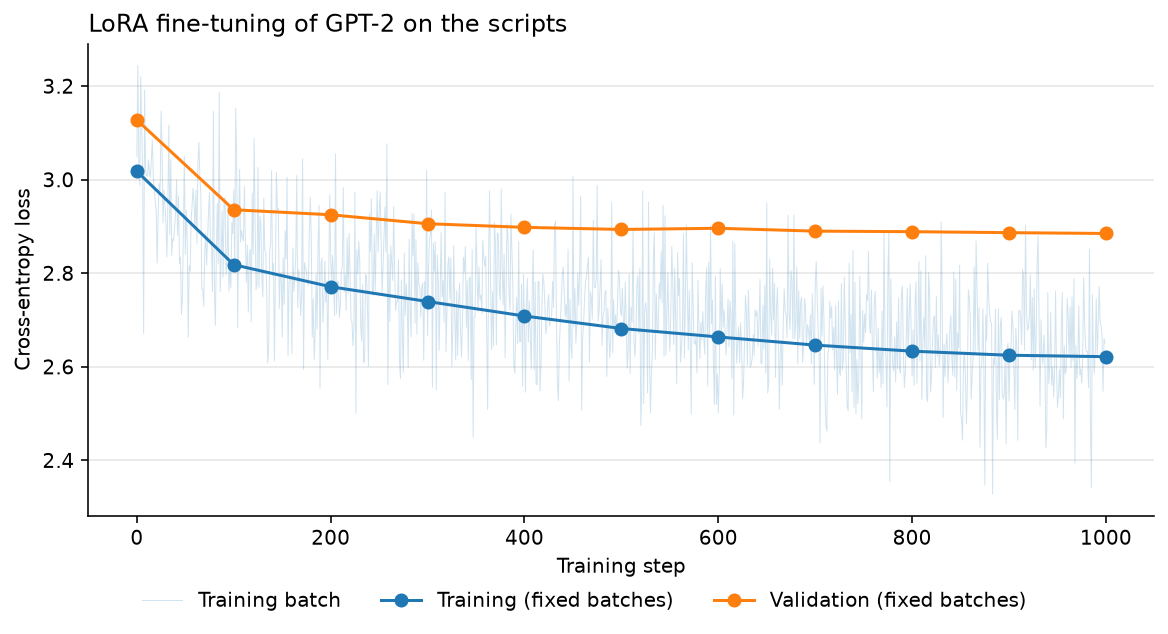

In [18]:
fig, ax = plt.subplots(figsize=(8, 4), dpi=144, layout="constrained")
ax.plot(step_losses, color="C0", alpha=0.2, linewidth=0.5, label="Training batch")
ax.plot(eval_steps, train_loss, color="C0", marker="o", label="Training (fixed batches)")
ax.plot(eval_steps, val_loss, color="C1", marker="o", label="Validation (fixed batches)")

ax.set(xlabel="Training step", ylabel="Cross-entropy loss")
ax.set_title("LoRA fine-tuning of GPT-2 on the scripts", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=len(labels),
    frameon=False,
)
plt.show()

Validation loss falls from 3.13 to 2.89, most of it in the first 100 steps, and is nearly flat after step 400. Training loss keeps falling, to 2.62, so the later steps mostly fit the training episodes and add little on held-out ones.

## After fine-tuning

The adapters trained on MLX hold MLX arrays, so they are converted back to NumPy before the default backend samples from the inference graph again, with the same prompt and seed as before training.

In [19]:
for parameter in lora_parameters:
    parameter.set_value(np.asarray(parameter.get_value()))

for seed in range(3):
    print(f"--- sample {seed + 1} ---")
    print(generate(script_prompt, n_tokens=120, temperature=0.8, seed=seed), end="\n\n")

--- sample 1 ---
Jerry: You ever notice nobody actually reads the terms and conditions?
Elaine: I read them once. It took me a whole weekend.
George: What is the point of reading the terms and conditions?
Elaine: I mean, I think, I'm sure we could surrender ourselves to that.
George: So, you tell Jerry, are you sure you're getting the results?
Jerry: Yeah, I know. I know, I know. I know.
George: I'm afraid I never will.
Jerry: You don't want to be alone?
Elaine: Yeah, when they finally do finish there's no way we'll be able to sleep.
Jerry: Well, if you ever have to?

--- sample 2 ---
Jerry: You ever notice nobody actually reads the terms and conditions?
Elaine: I read them once. It took me a whole weekend.
George: No way, Jerry. I keep two files, one for you and one for me.
Jerry: You're kidding me.
Elaine: No, no. It's a whole month, actually.
George: How long do you think it takes to put the two files together?
Elaine: Two weeks.
Jerry: Okay, so then he'll be late for dinner in five

Plain GPT-2 picks up the `Speaker: line` format from the prompt but drifts to unrelated subjects and invents new speakers. After fine-tuning, all three samples keep to the show's main characters, trade short lines about everyday errands, and one adds stage directions in parentheses, as the scripts do. The text still loses the thread within a few turns and repeats itself.

## Perplexity

Perplexity is the exponential of the mean cross-entropy per token: the number of equally likely tokens the model is, on average, choosing between. Each split is scored in full, in consecutive windows of `block_size` tokens, once with the pretrained graph and once with the adapters.

In [20]:
evaluate_pretrained_loss = pytensor.function(
    inputs=[train_tokens, targets],
    outputs=CrossEntropy(expect_logits=True)(targets, train_logits),
    mode="MLX",
)


def consecutive_batches(ids):
    n_windows = (len(ids) - 1) // block_size
    starts = np.arange(n_windows - n_windows % batch_size) * block_size
    for batch_starts in starts.reshape(-1, batch_size):
        windows = batch_starts[:, None] + np.arange(block_size)
        yield ids[windows], ids[windows + 1]


def perplexity(evaluate, ids):
    return np.exp(np.mean([np.array(evaluate(X, y)) for X, y in consecutive_batches(ids)]))

In [21]:
pd.DataFrame(
    {
        "Pretrained": [perplexity(evaluate_pretrained_loss, ids) for ids in (train_ids, val_ids)],
        "LoRA fine-tuned": [perplexity(evaluate_loss, ids) for ids in (train_ids, val_ids)],
    },
    index=["Training episodes", "Validation episodes"],
).astype(float).round(1)

,Pretrained,LoRA fine-tuned
Training episodes,20.7,14.1
Validation episodes,22.5,17.8


Fine-tuning lowers validation perplexity from 22.5 to 17.8, about a fifth. Training perplexity falls further, from 20.7 to 14.1, and the gap between the two splits grows from 1.8 to 3.7. Part of what the adapters learned is specific to the training episodes, which matches the flattening validation curve.

## References

```{bibliography}
```

## Authors

- Created by Jesse Grabowski, November 8, 2026

## Watermark

In [22]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Sun, 08 Nov 2026

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.16.1

Compiler    : Clang 20.1.8 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

csv            : 1.0
huggingface_hub: 2.4.0
json           : 2.0.9
matplotlib     : 3.11.2
numpy          : 2.5.4
pandas         : 3.0.5
pytensor       : 3.3.8
pytensor_ml    : 0.4.0
tokenizers     : 0.23.3
tqdm           : 4.70.1

Watermark: 2.6.0



# Thumbnail Image

The cell below draws this notebook's card image for the docs gallery: a block of one pretrained weight next to the trained adapter factors that correct it. Its `gallery-thumbnail` tag selects it as the thumbnail, and its `remove-cell` tag, shared with this heading, keeps both off the rendered page.

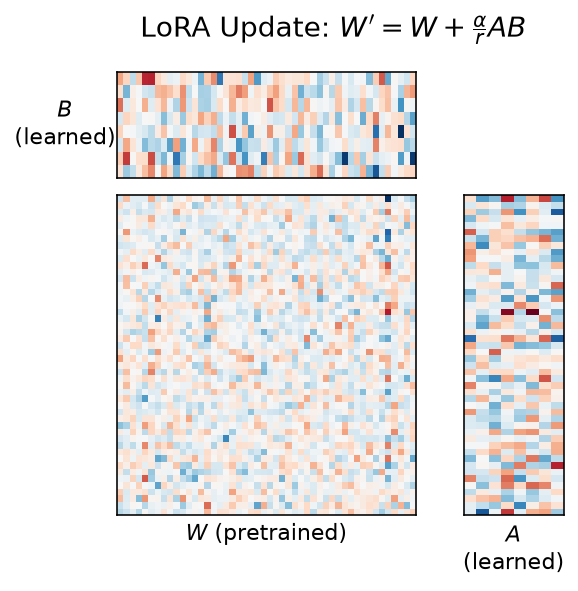

In [23]:
weight_name = "h_11_ff_fc_in_W"
by_name = {parameter.name: parameter for parameter in [*lora_replacements, *lora_parameters]}
block = 48

panels = {
    "W": by_name[weight_name].get_value()[:block, :block],
    "A": by_name[f"{weight_name}_lora_down"].get_value()[:block],
    "B": by_name[f"{weight_name}_lora_up"].get_value()[:, :block],
}

fig = plt.figure(figsize=(4, 4), dpi=144)
grid = fig.add_gridspec(
    nrows=2,
    ncols=3,
    width_ratios=[block, 4, rank * 2],
    height_ratios=[rank * 2, block],
    wspace=0.08,
    hspace=0.08,
)
locations = {"W": grid[1, 0], "A": grid[1, 2], "B": grid[0, 0]}

axes = {}
for label, values in panels.items():
    ax = fig.add_subplot(locations[label])
    limit = np.abs(values).max()
    ax.imshow(
        values, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto", interpolation="nearest"
    )
    ax.set_xticks([])
    ax.set_yticks([])
    axes[label] = ax

axes["W"].set_xlabel("$W$ (pretrained)", fontsize=11)
axes["A"].set_xlabel("$A$\n(learned)", fontsize=11)
axes["B"].set_ylabel("$B$\n(learned)", fontsize=11, rotation=0, labelpad=26, va="center")
fig.suptitle(r"LoRA Update: $W^\prime = W + \frac{\alpha}{r} A B$", fontsize=14)
plt.show()